# Analyzing ClinVar variants

In [1]:
import os
import polars as pl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# import concurrent.futures
# aa_single_to_three = {
#     'A': 'Ala',  # Alanine
#     'R': 'Arg',  # Arginine
#     'N': 'Asn',  # Asparagine
#     'D': 'Asp',  # Aspartic acid
#     'C': 'Cys',  # Cysteine
#     'Q': 'Gln',  # Glutamine
#     'E': 'Glu',  # Glutamic acid
#     'G': 'Gly',  # Glycine
#     'H': 'His',  # Histidine
#     'I': 'Ile',  # Isoleucine
#     'L': 'Leu',  # Leucine
#     'K': 'Lys',  # Lysine
#     'M': 'Met',  # Methionine
#     'F': 'Phe',  # Phenylalanine
#     'P': 'Pro',  # Proline
#     'S': 'Ser',  # Serine
#     'T': 'Thr',  # Threonine
#     'W': 'Trp',  # Tryptophan
#     'Y': 'Tyr',  # Tyrosine
#     'V': 'Val'   # Valine
# }

variant_annot = [
    "hg19_chr","genename","Ensembl_geneid","Ensembl_proteinid",
    "Uniprot_acc","Uniprot_entry",
    "aapos","aaref","aaref_3","aaalt","aaalt_3",#"aa_change",
    "Ensembl_transcriptid","hg19_pos(1-based)","HGVSc_snpEff","HGVSp_snpEff",
    "HGVSc_VEP","HGVSp_VEP",
]

## Loading the dbnsfp snps

In [2]:
df_clinvar = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants.parquet")
# df_clinvar.filter(pl.col("aaalt").str.len_chars() == 1).collect()

# df_clinvar_dup = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot.parquet")
# df_clinvar_dup.collect()

df_clinvar.collect()

predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

## AI-predictor scores distribution

In [3]:
# Define the mapping from new column names to original column names
score_mapping = {
    "esm1b": "ESM1b_score",
    "alphamissense": "AlphaMissense_score",
    "provean": "PROVEAN_score"
}

df_clinvar_sampled_plots = df_clinvar.with_columns(
    [
        pl.col(score_mapping[var])
          .replace(".", None)
          .cast(pl.Float64)
          .alias(var)
        for var in score_mapping.keys()
    ]
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")).collect()

df_clinvar_sampled_plots

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,esm1b,alphamissense,provean
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f64
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""","""-""","""-""","""1279G>A ""","""Val427Met""","""NC_000021.9:13630977:G:A""","""NM_174981.6""",1,"""2_Benign""",-5.093,0.12,-0.28
"""1641486""","""21""",14109008,"""T""","""G""","""H""","""P""","""rs773252276""","""21""","""15481329""","""21""","""14403200""","""360""","""LIPI""","""ENSG00000188992""","""ENST00000400211""","""ENSP00000383072""","""H0Y3S0""","""H0Y3S0_HUMAN""",""".""",""".""","""c.1079A>C""","""p.His360Pro""",""".""","""Y""","""1""",""".""",""".""","""-""","""CAC""","""2""","""0""",""".""","""T/T""","""T/T""","""T/T""","""T/T""",…,"""not provided""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",14109008,14109008,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA511421600""",2,1641486,14109008,"""T""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV002456108""","""-""","""-""","""1368A>C ""","""Thr456=""","""NC_000021.9:14109008:T:G""","""NM_001302998.2""",1,"""2_Benign""",null,null,null
"""2336004""","""21""",14227009,"""A""","""G""","""K""","""E""","""rs548298378""","""21""","""15599330""","""21""","""14521201""","""188""","""RBM11""","""ENSG00000185272""","""ENST00000400577""","""ENSP00000383421""","""P57052""","""RBM11_HUMAN""","""c.562A>G""","""p.Lys188Glu""","""c.562A>G""","""p.Lys188Glu""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AAA""","""1""","""0""","""A""","""./.""","""./.""","""./.""","""./.""",…,"""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",14227009,14227009,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317626207""",2,2336004,14227009,"""A""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003674731""","""-""","""-""","""562A>G ""","""Lys188Glu""","""NC_000021.9:14227009:A:G""","""NM_144770.5""",1,"""2_Benign""",-6.57,0.059,0.67
"""3313159""","""21""",1422

In [4]:
def plot_ai_var_pred_dist(df, score_mapping, title):
    # Create a FacetGrid for multiple subplots
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5)) ## , sharey=True
    hue_order = sorted(df["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
    # Loop through variables and create subplots
    for ax, var in zip(axes, score_mapping.keys()):
        sns.kdeplot(
            data=df,
            x=var,
            hue="clinvar_clnsig_clean",
            hue_order=hue_order,
            # kde=True,
            ax=ax,
            palette="Set1"
        )
        ax.set_title(var)
    
    plt.suptitle(title, y=.96)    
    plt.tight_layout()
    plt.show()

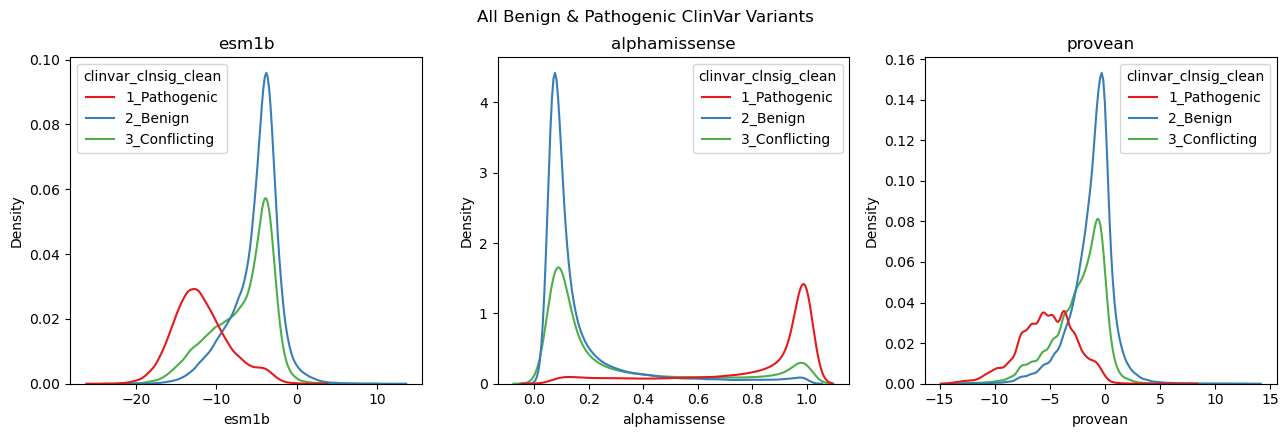

In [36]:
plot_ai_var_pred_dist(df_clinvar_sampled_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "All Benign & Pathogenic ClinVar Variants")

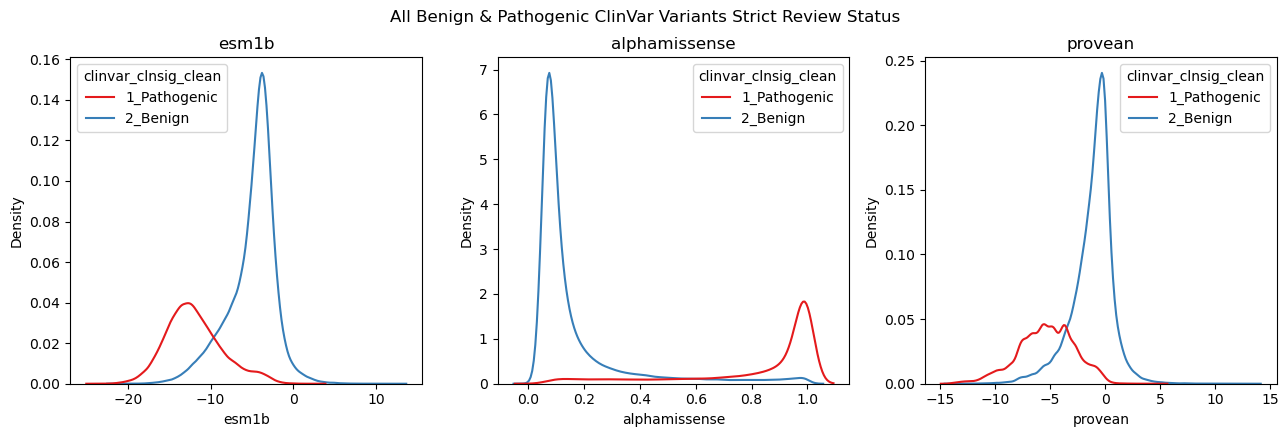

In [37]:
plot_ai_var_pred_dist(df_clinvar_sampled_plots.filter(pl.col("ReviewStatus").is_in([
                            'practice guideline'
                            'reviewed by expert panel',
                            'criteria provided, multiple submitters, no conflicts',
                            'criteria provided, single submitter'
                        ])).select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "All Benign & Pathogenic ClinVar Variants Strict Review Status")

In [14]:
df_clinvar_sampled_plots.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")=="3_Conflicting")).select(predictor_algos+list(score_mapping.keys()))

PROVEAN_score,PROVEAN_converted_rankscore,PROVEAN_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,clinvar_id,clinvar_clnsig,clinvar_trait,clinvar_review,clinvar_hgvs,clinvar_var_source,clinvar_MedGen_id,clinvar_OMIM_id,clinvar_Orphanet_id,clinvar_nt_change,clinvar_aa_change,clinvar_clnsig_clean,esm1b,alphamissense,provean
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,cat,f64,f64,f64
"""-4.32""","""0.76686""","""D""","""-12.626""","""0.87794""","""D""","""0.9306""","""0.85031""","""P""","""12982""","""Uncertain_significance|drug_re…","""RYR1-related_disorder|Central_…","""reviewed_by_expert_panel""","""NC_000019.10:g.38580440G>A""","""ClinGen:CA024187|OMIM:180901.0…","""CN239331|C0751951|C3661900|C29…","""117000|145600""","""597|423|423""","""14582G>A ""","""Arg4861His""","""3_Conflicting""",-12.626,0.9306,-4.32


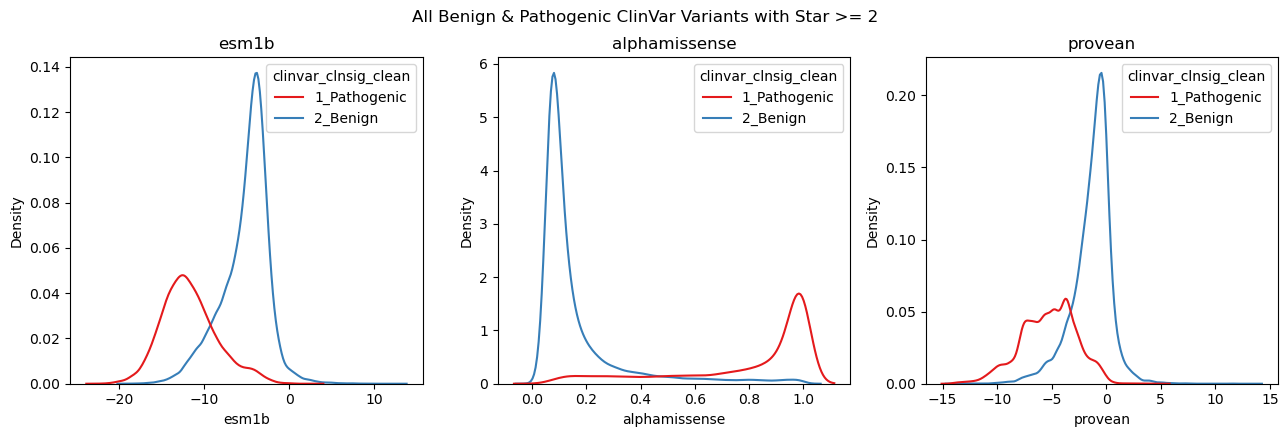

In [ ]:
## Among the Star>=2 variants, there is one conflicting variant, filter it out:
plot_ai_var_pred_dist(df_clinvar_sampled_plots.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")!="3_Conflicting")).select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "All Benign & Pathogenic ClinVar Variants with StarStatus >= 2")

## AI-predictor scores across structure

In [5]:
df_clinvar_scores = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants_plddt_rsa.parquet")
df_clinvar_scores = df_clinvar_scores.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
)

print(df_clinvar_scores.collect())
print(df_clinvar_scores.filter(~pl.col("plddt_f32").is_nan()).collect())

shape: (1_649_580, 433)
┌────────────┬──────┬──────────────┬─────┬───┬───────┬──────────┬───────────┬──────────┐
│ clinvar_id ┆ #chr ┆ pos(1-based) ┆ ref ┆ … ┆ plddt ┆ rsa      ┆ plddt_f32 ┆ rsa_f32  │
│ ---        ┆ ---  ┆ ---          ┆ --- ┆   ┆ ---   ┆ ---      ┆ ---       ┆ ---      │
│ str        ┆ str  ┆ i64          ┆ str ┆   ┆ f64   ┆ f64      ┆ f32       ┆ f32      │
╞════════════╪══════╪══════════════╪═════╪═══╪═══════╪══════════╪═══════════╪══════════╡
│ 2361281    ┆ 21   ┆ 13628442     ┆ G   ┆ … ┆ 32.34 ┆ 0.953846 ┆ 32.34     ┆ 0.953846 │
│ 2599176    ┆ 21   ┆ 13630941     ┆ G   ┆ … ┆ 58.03 ┆ 0.06338  ┆ 58.029999 ┆ 0.06338  │
│ 2486768    ┆ 21   ┆ 13630977     ┆ G   ┆ … ┆ 32.9  ┆ 0.978873 ┆ 32.900002 ┆ 0.978873 │
│ 2277922    ┆ 21   ┆ 13631057     ┆ A   ┆ … ┆ 31.88 ┆ 0.995968 ┆ 31.879999 ┆ 0.995968 │
│ 3308991    ┆ 21   ┆ 13639588     ┆ A   ┆ … ┆ 75.35 ┆ 0.492958 ┆ 75.349998 ┆ 0.492958 │
│ …          ┆ …    ┆ …            ┆ …   ┆ … ┆ …     ┆ …        ┆ …         ┆ …       

In [6]:
df_clinvar_w_scores = df_clinvar_scores.filter(
    ~pl.col("plddt_f32").is_nan()
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("rsa_cat"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("plddt_cat"),
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("B"))
        .then(pl.lit("2_Benign"))
        .when(pl.col("AlphaMissense_pred").str.contains("P"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("A"))
        .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AM_pred"),
    (
        pl.when(pl.col("PROVEAN_pred").str.contains("D"))
        .then(pl.lit("1_Damaging"))
        .when(pl.col("PROVEAN_pred").str.contains("N"))
        .then(pl.lit("2_Neutral"))
        .otherwise(pl.lit("."))
    ).alias("Provean_pred"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("D"))
        .then(pl.lit("1_Deleterious"))
        .when(pl.col("ESM1b_pred").str.contains("T"))
        .then(pl.lit("2_Tolerated"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_pred")
)

In [7]:
# df_clinvar_w_scores.filter((pl.col("AlphaMissense_pred")!=".")).collect()
# df_clinvar_w_scores.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")).collect()
# df_clinvar_w_scores.filter((pl.col("clinvar_clnsig_clean")=="2_Benign")).collect()

### Percentage of accurate prediction per pLDDT and RSA category

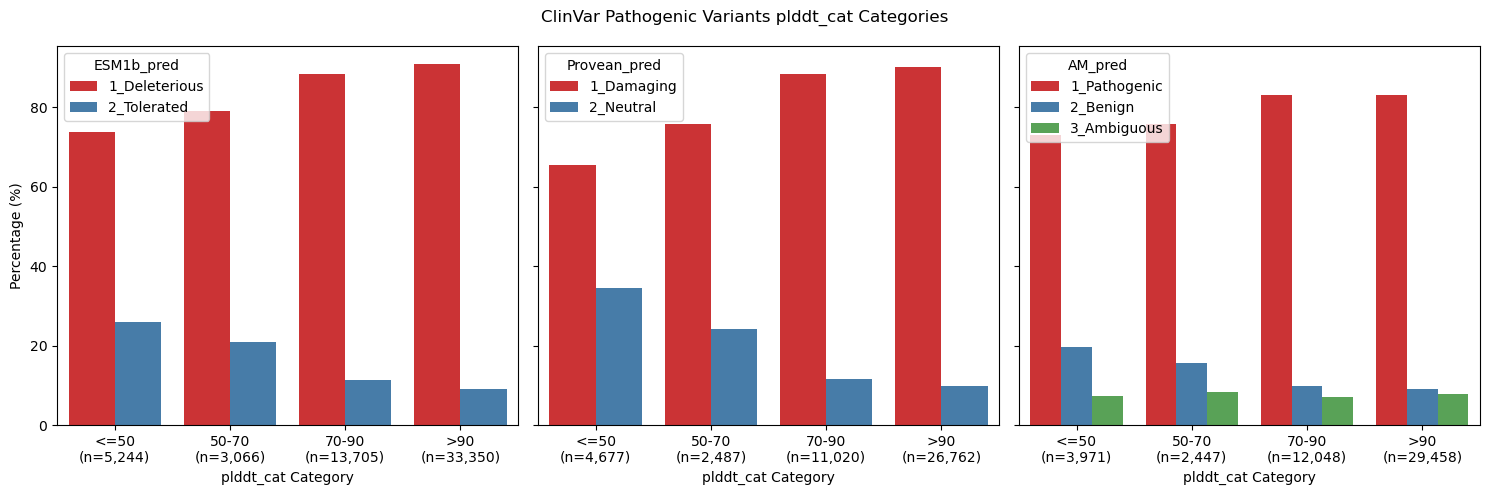

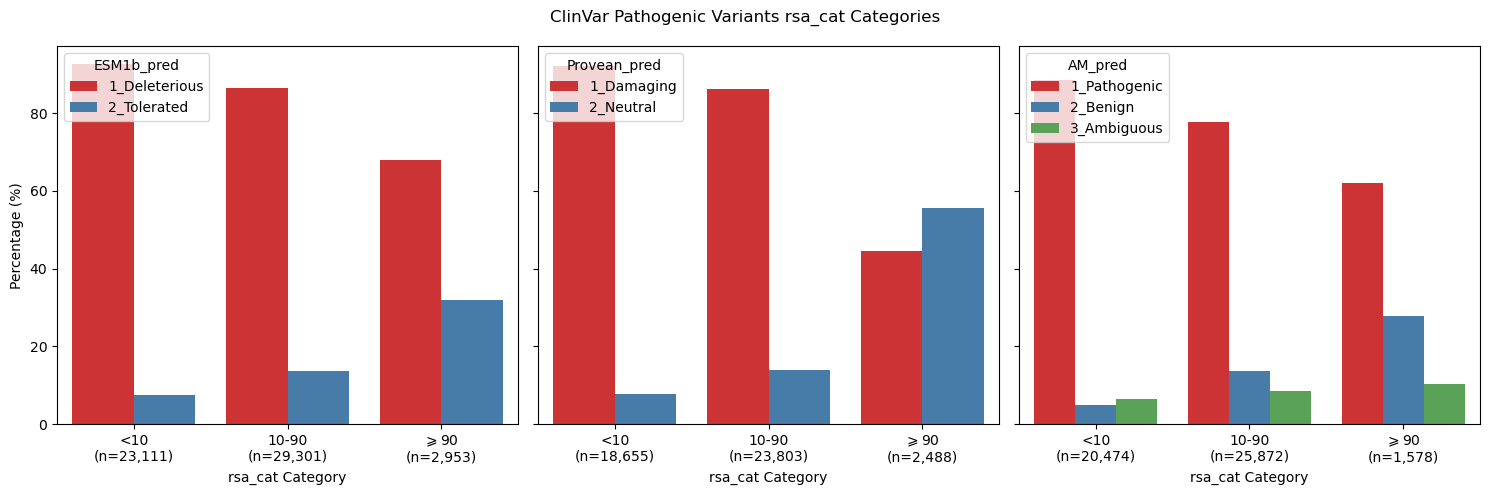

In [8]:
# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", "$\geqslant$90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100

        # print(percentage_df)
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        # Get the current x-tick labels
        current_ticks = axes[preds.index(pred)].get_xticks()
        new_labels = []
        # For each category, add the total count to the label
        for category in pred_cat[cat]:
            # Get the total for this category
            total = subset[subset[cat] == category]['total'].iloc[0]
            # Create new label with category and total
            new_label = f"{category}\n(n={total:,})"
            new_labels.append(new_label)

        # Set the new x-tick labels
        # Explicitly set the tick positions and then the labels
        axes[preds.index(pred)].set_xticks(current_ticks[:len(new_labels)])
        axes[preds.index(pred)].set_xticklabels(new_labels)

        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Pathogenic Variants {cat} Categories")
    plt.tight_layout()
    plt.show()

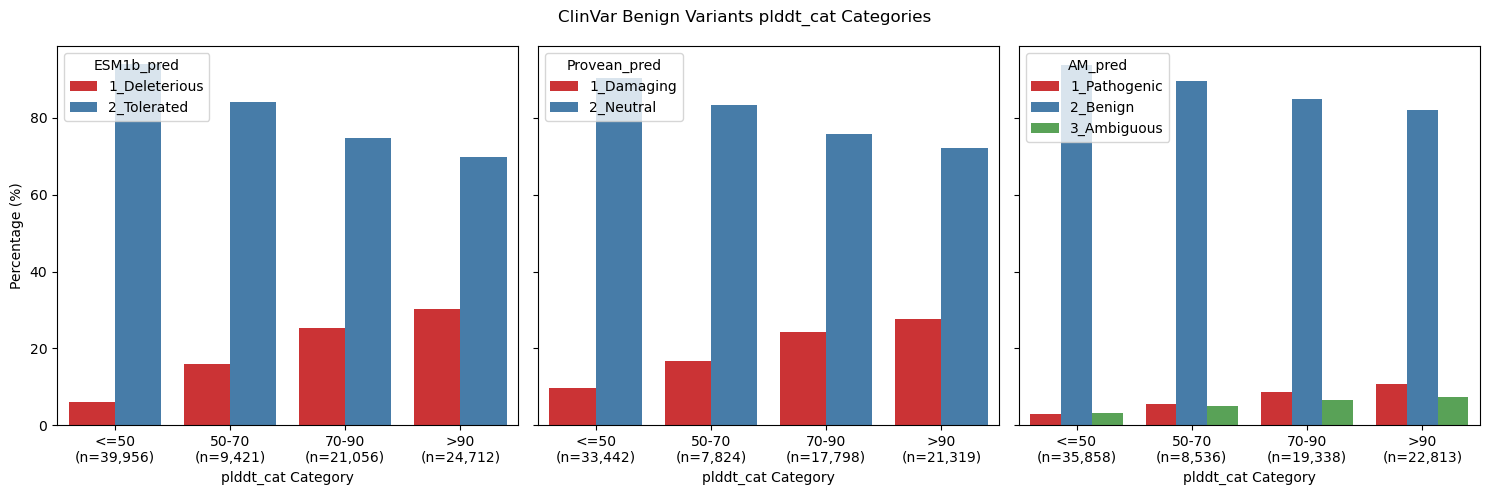

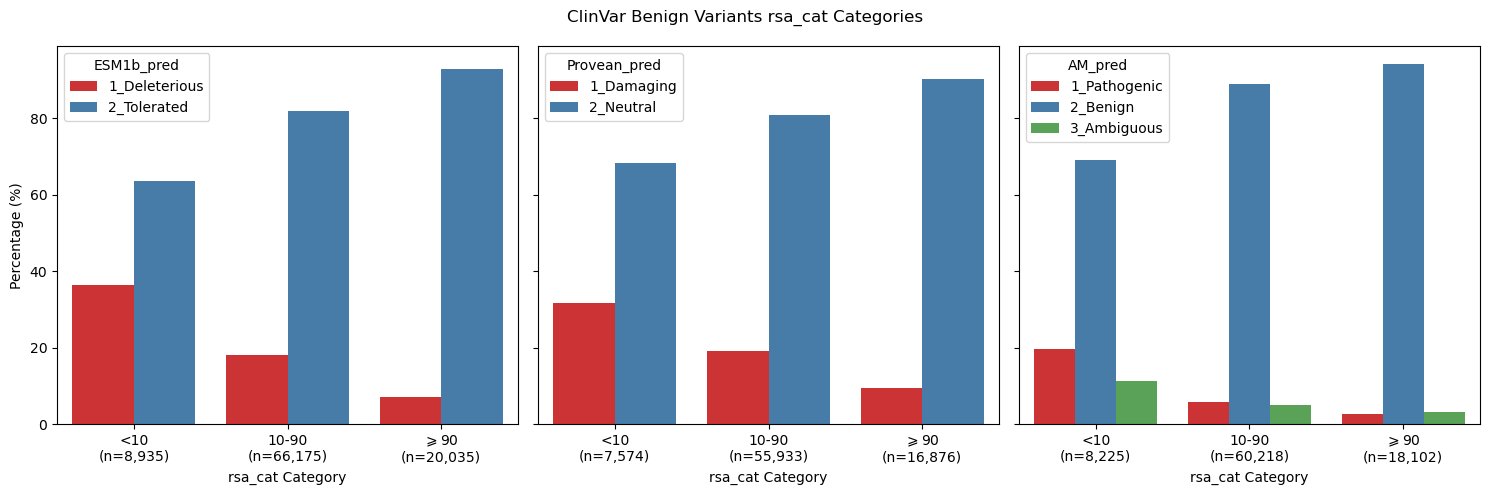

In [9]:
# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", "$\geqslant$90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="2_Benign")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        # Get the current x-tick labels
        current_ticks = axes[preds.index(pred)].get_xticks()
        new_labels = []
        # For each category, add the total count to the label
        for category in pred_cat[cat]:
            # Get the total for this category
            total = subset[subset[cat] == category]['total'].iloc[0]
            # Create new label with category and total
            new_label = f"{category}\n(n={total:,})"
            new_labels.append(new_label)

        # Set the new x-tick labels
        # Explicitly set the tick positions and then the labels
        axes[preds.index(pred)].set_xticks(current_ticks[:len(new_labels)])
        axes[preds.index(pred)].set_xticklabels(new_labels)
        
        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Benign Variants {cat} Categories")
    plt.tight_layout()
    plt.show()

### PR curves per pLDDT and RSA category

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from scipy.stats import ttest_ind
import sys
sys.path.insert(1, "scripts/")
from yogiroc import *

df_clinvar_w_scores = df_clinvar_w_scores.with_columns(
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("1_Pathogenic"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("2_Benign"))
        .then(pl.lit("2_Benign"))
        # .when(pl.col("AlphaMissense_pred").str.contains("A"))
        # .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AlphaMissense_ClinVar"),
    (
        pl.when(pl.col("Provean_pred").str.contains("1_Damaging"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("Provean_pred").str.contains("2_Neutral"))
        .then(pl.lit("2_Benign"))
        .otherwise(pl.lit("."))
    ).alias("Provean_ClinVar"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("1_Deleterious"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("ESM1b_pred").str.contains("2_Tolerated"))
        .then(pl.lit("2_Benign"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_ClinVar")
).collect()

set2_palette = sns.color_palette("Set1")
methods = ["PROVEAN_converted_rankscore","ESM1b_rankscore","AlphaMissense_rankscore"]
categories = ["plddt_cat", "rsa_cat"]

#### Raw PR curves

__1. AlphaMissense_score:__

AlphaMissense is a unsupervised model for predicting the pathogenicity of human missense variants
	by incorporating structural context of an AlphaFold-derived system. The AlphaMissense score ranges from 0 to 1. 
	__The larger the score, the more likely the variant is pathogenic.__

__2. ESM1b_score:__

ESM1b scores are log-likelihood ratio (LLR) scores for predicting the pathogenic effects of coding
	variants based on a 650-million-parameter protein language model, ESM1b. The range of ESM1b score in dbNSFP 
	is from -24.538 to 6.937. 
	__The smaller the score, the more likely the variant is pathogenic.__


__3. PROVEAN_score:__

PROVEAN score (PROVEANori). Scores range from -14 to 14. 
	__The smaller the score the more likely the SNP has damaging effect.__

In [38]:
# def plot_raw_pr_curve(df, postive_label, methods, categories=categories):
#     for category in categories:
#         fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
#         for met in methods:
#             plddt_cats = sorted(df[category].unique().to_list())
#             for cat in plddt_cats:
#                 df_clin_per_method = df.filter(
#                     (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))&(pl.col(category)==cat)
#                 ).with_columns(
#                     (
#                         pl.when(pl.col("clinvar_clnsig_clean")==postive_label)
#                         .then(1) ## method_pos_label[met]
#                         .otherwise(0) ## 1-method_pos_label[met]
#                     ).alias("clinvar_label"),
#                     (
#                         pl.col(met).replace(".", None).cast(pl.Float64)
#                     ).alias(met)
#                 ).drop_nulls(
#                     subset=["clinvar_clnsig_clean", met]
#                 )

#                 # Compute performance table over thresholds.
#                 precision, recall, thresholds = precision_recall_curve(df_clin_per_method["clinvar_label"], 
#                                                                        df_clin_per_method[met])
#                 # For a fair baseline, use the first row (threshold = -∞; all predicted positive)
#                 prior = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
                
#                 # Adjust precision using the balance_prec function.
#                 precision_balanced = [balance_prec(p, prior) for p in precision]

#                 pr_table = pd.DataFrame({
#                     "recall": recall,
#                     "precision": precision,
#                     "balanced_prec": precision_balanced
#                 })

#                 # Optionally monotonize the balanced precision to smooth out dips.
#                 # pr_table = pr_table.sort_values('recall', ascending=False)
#                 pr_table['mono_precision'] = monotonize(pr_table['precision'].values)
#                 pr_table['mono_balanced_precision'] = monotonize(pr_table['balanced_prec'].values)

#                 ap = calc_auc(pr_table["recall"].values, pr_table['mono_precision'].values)
#                 axes[methods.index(met)].plot(pr_table["recall"], pr_table["mono_precision"], 
#                                             label=f"{cat}: {ap:.2f}", color=set2_palette[plddt_cats.index(cat)]) ## marker='.', 
#                 chance_level = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
#                 axes[methods.index(met)].axhline(y=chance_level, color=set2_palette[plddt_cats.index(cat)], ls="--")
            
#             handles, labels = axes[methods.index(met)].get_legend_handles_labels()
#             order = [3,1,0,2] if "plddt" in category else [2,1,0]
#             axes[methods.index(met)].legend([handles[idx] for idx in order], [labels[idx] for idx in order], 
#                                             loc="lower left",
#                                             title=f"AUPRC by {category}")
#             axes[methods.index(met)].set_xlabel('Recall')
#             axes[methods.index(met)].set_title(met.split("_")[0])

#         axes[0].set_ylabel('Precision')
#         plt.subplots_adjust(wspace=0.04)


def bootstrap_ap(df, met, n_bootstrap=1000, random_state=None):
    """
    Bootstrap the adjusted AUPRC for a given dataframe.
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame for a given RSA category (must contain columns "clinvar_label" and the score column met).
    met : str
        Column name for the predictor score.
    n_bootstrap : int, optional
        Number of bootstrap samples (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    boot_ap : np.ndarray
        Array of bootstrap AUPRC values computed from the adjusted PR curve.
    """
    boot_ap = []
    rng = np.random.default_rng(random_state)
    for _ in range(n_bootstrap):
        boot_sample = df.sample(frac=1, replace=True)
        precision, recall, thresholds = precision_recall_curve(boot_sample["clinvar_label"], boot_sample[met])
        prior = boot_sample["clinvar_label"].sum() / boot_sample.shape[0]
        precision_balanced = [balance_prec(p, prior) for p in precision]
        pr_table = pd.DataFrame({
            "recall": recall,
            "precision": precision,
            "balanced_prec": precision_balanced
        })
        pr_table['mono_precision'] = monotonize(pr_table['precision'].values)
        pr_table['mono_balanced_precision'] = monotonize(pr_table['balanced_prec'].values)
        # We reverse recall if necessary (as in our calc_auc fix) so that area is positive.
        ap_val = calc_auc(-pr_table["recall"].values, pr_table["mono_balanced_precision"].values)
        boot_ap.append(ap_val)
    return np.array(boot_ap)


def plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label, methods, monotonized_flag, balanced_flag, categories=categories, set2_palette=set2_palette, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    ap_results_dict, sig_results_dict = {}, {}
    for category in categories:
        fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 5))
        if len(methods) == 1:
            axes = [axes]
            
        ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
        significance = {}  # to store pairwise significance p-values per method
        
        for m_idx, met in enumerate(methods):
            ap_results[met] = {}
            # Get sorted RSA categories.
            plddt_cats = sorted(df_clinvar_w_scores[category].unique().to_list())
            for cat in plddt_cats:
                # Filter data for current category and valid clinical labels.
                df_clin_per_method = df_clinvar_w_scores.filter(
                    (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])) &
                    (pl.col(category) == cat)
                ).with_columns(
                    (
                        pl.when(pl.col("clinvar_clnsig_clean") == pos_label)
                        .then(1)
                        .otherwise(0)
                    ).alias("clinvar_label"),
                    (
                        pl.col(met).replace(".", None).cast(pl.Float64)
                    ).alias(met)
                ).drop_nulls(subset=["clinvar_clnsig_clean", met])
                
                # Convert to pandas DataFrame.
                df_pd = df_clin_per_method.to_pandas()
                # Convert clinvar_label to boolean.
                truth = df_pd["clinvar_label"].astype(bool)
                # Create a scores DataFrame (with one column).
                scores = df_pd[[met]]
                # Create the YogiROC2 object using the new YogiROC2() constructor.
                yrobj = YogiROC2(truth, scores, names=[met], high=True)
                # Get the performance table from the YogiROC2 object.
                table = yrobj.tables[met]

                if (monotonized_flag and balanced_flag):
                    table = table.dropna()
                precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
                recall = table["tpr_sens"].values
                # print(precision)
                # print(recall)
                ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
                ap_results[met][cat] = {"AUPRC": ap}

                # Plot the adjusted PR curve.
                axes[m_idx].plot(100 * recall, 100 * precision,
                                label=f"{cat}: {ap:.2f}",
                                color=set2_palette[plddt_cats.index(cat)])
                # Plot chance level as a horizontal dashed line.
                prior = np.sum(truth) / df_pd.shape[0]
                axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
                
            #     # Sample PRC paths using the new sample_prcs() function.
            #     random_paths = sample_prcs(table)
            #     # Infer confidence intervals for the PR curve.
            #     ci_df = infer_prc_CI(random_paths, nbins=50)
            #     # (Optional: you could adjust the CI columns using balance_prec if desired.)
            #     axes[m_idx].fill_between(100 * ci_df["recall"],
            #                              100 * ci_df["0.025"],
            #                              100 * ci_df["0.975"],
            #                              color=set2_palette[plddt_cats.index(cat)],
            #                              alpha=0.1)
            #     # Bootstrap the adjusted AUPRC for significance testing.
            #     boot_ap = []
            #     for _ in range(n_bootstrap):
            #         boot_idx = rng.choice(df_pd.index, size=len(df_pd), replace=True)
            #         boot_df = df_pd.loc[boot_idx]
            #         boot_truth = boot_df["clinvar_label"].astype(bool)
            #         boot_scores = boot_df[[met]]
            #         boot_yrobj = yr2(boot_truth, boot_scores, names=[met], high=True)
            #         boot_table = boot_yrobj.tables[met]
            #         boot_adj_prec = configure_prec(boot_table, monotonized=True, balanced=True)
            #         boot_ap_val = calc_auc(boot_table["tpr_sens"].values, boot_adj_prec)
            #         boot_ap.append(boot_ap_val)
            #     ap_results[met][cat]["boot_ap"] = np.array(boot_ap)
            # # Now, perform pairwise significance testing across RSA categories.
            # categories = list(ap_results[met].keys())
            # n_cat = len(categories)
            # pvals = np.empty((n_cat, n_cat))
            # for i in range(n_cat):
            #     for j in range(n_cat):
            #         if i == j:
            #             pvals[i, j] = np.nan
            #         else:
            #             stat, p = ttest_ind(ap_results[met][categories[i]]["boot_ap"],
            #                                   ap_results[met][categories[j]]["boot_ap"],
            #                                   equal_var=False)
            #             pvals[i, j] = p
            # significance[met] = pd.DataFrame(pvals, index=categories, columns=categories)
            
            # Customize the subplot.
            handles, labels = axes[methods.index(met)].get_legend_handles_labels()
            order = [2,1,0] if "rsa" in category else [3,1,0,2]
            precision_label = "Precision (%)"
            title = f"AUPRC by {category}"
            
            if balanced_flag:
                precision_label = "Balanced " + precision_label
                title = "Adj. " + title
            if monotonized_flag:
                precision_label = "Monotonized " + precision_label
                title = "Adj. " + title

            axes[m_idx].legend([handles[idx] for idx in order], [labels[idx] for idx in order], 
                            loc="lower left",
                            title=title)
            axes[m_idx].set_xlabel("Recall (%)")
            axes[m_idx].set_ylabel(precision_label)
            axes[m_idx].set_title(met.split("_")[0])

        ap_results_dict[category] = ap_results
        sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return ap_results_dict, sig_results_dict

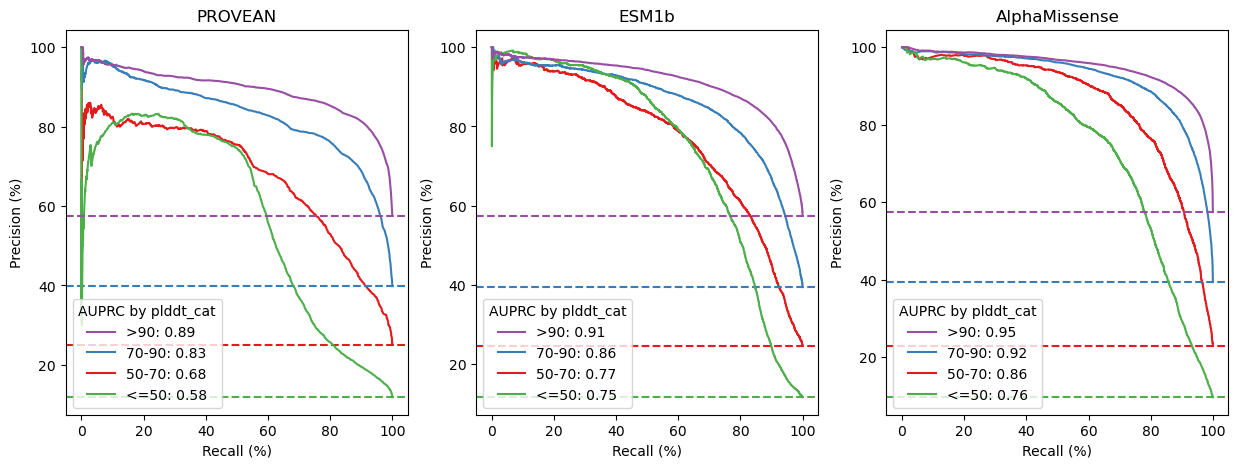

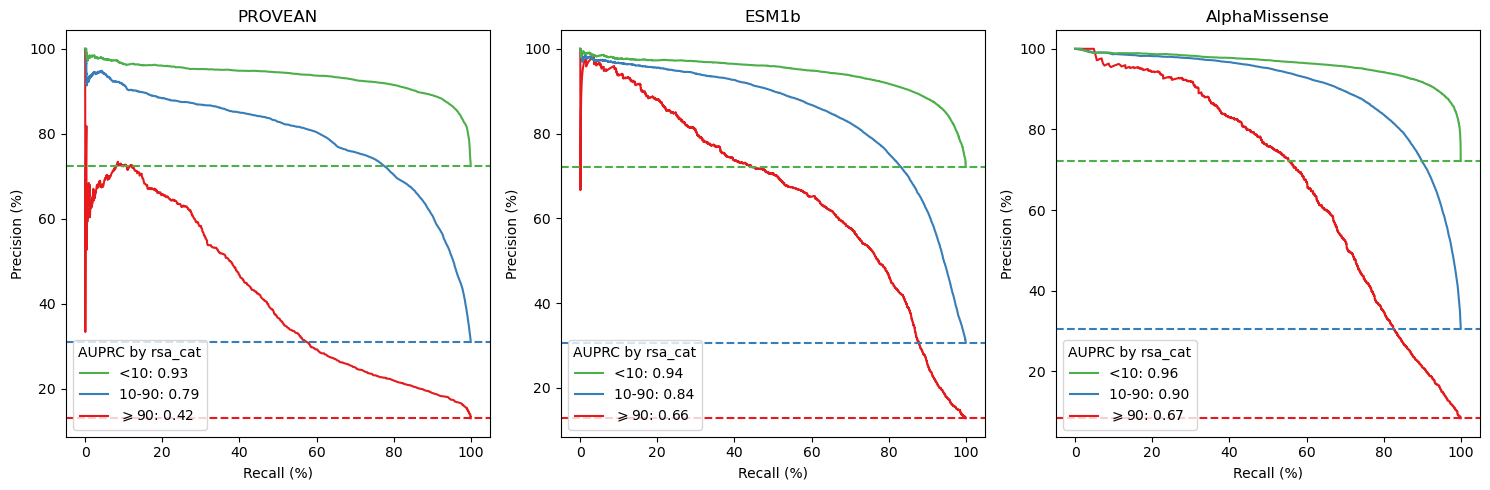

({'plddt_cat': {'PROVEAN_converted_rankscore': {'50-70': {'AUPRC': 0.6787479019218369},
    '70-90': {'AUPRC': 0.8282400932318823},
    '<=50': {'AUPRC': 0.5761847308787629},
    '>90': {'AUPRC': 0.8915720750356175}},
   'ESM1b_rankscore': {'50-70': {'AUPRC': 0.771288433530744},
    '70-90': {'AUPRC': 0.8582883178822357},
    '<=50': {'AUPRC': 0.7476343322950291},
    '>90': {'AUPRC': 0.9137332046078475}},
   'AlphaMissense_rankscore': {'50-70': {'AUPRC': 0.8578575461396408},
    '70-90': {'AUPRC': 0.9214825809086811},
    '<=50': {'AUPRC': 0.7551932880168829},
    '>90': {'AUPRC': 0.9491317387829085}}},
  'rsa_cat': {'PROVEAN_converted_rankscore': {'$\\geqslant$90': {'AUPRC': 0.41540096871087673},
    '10-90': {'AUPRC': 0.7900120088902844},
    '<10': {'AUPRC': 0.9346856502476004}},
   'ESM1b_rankscore': {'$\\geqslant$90': {'AUPRC': 0.657215025701311},
    '10-90': {'AUPRC': 0.8424425468399883},
    '<10': {'AUPRC': 0.9423426659877714}},
   'AlphaMissense_rankscore': {'$\\geqslant$90'

In [39]:
plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label="1_Pathogenic", methods=methods, monotonized_flag=False, balanced_flag=False)

In [40]:
# plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label="2_Benign", methods=methods, monotonized_flag=False, balanced_flag=False)

#### Monotonize the precision in the PR curve

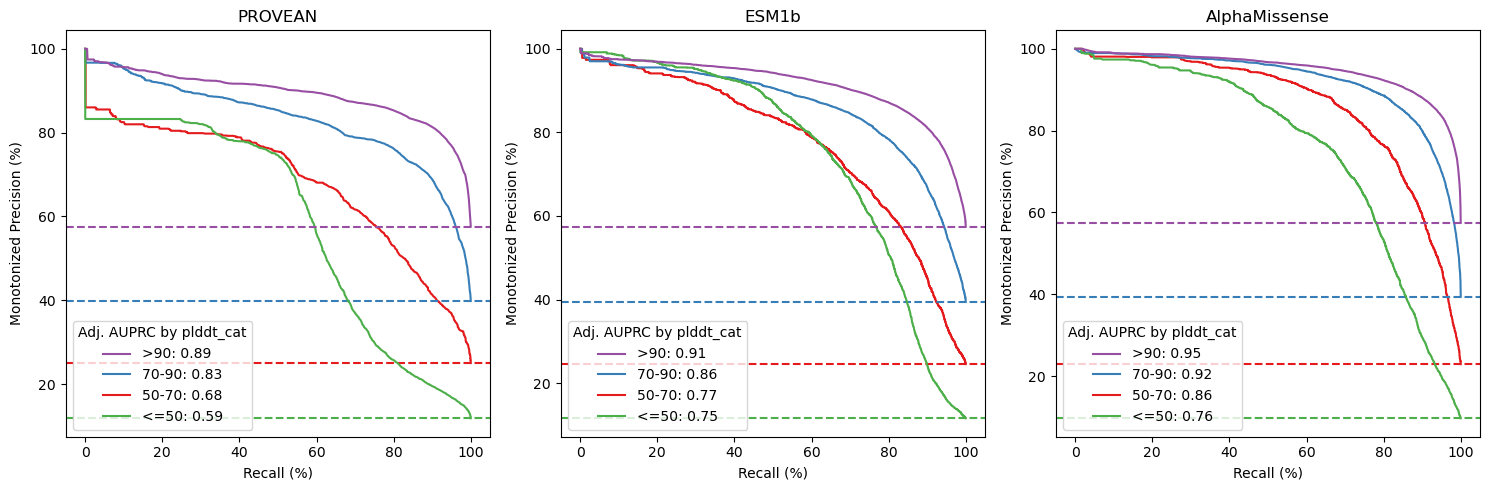

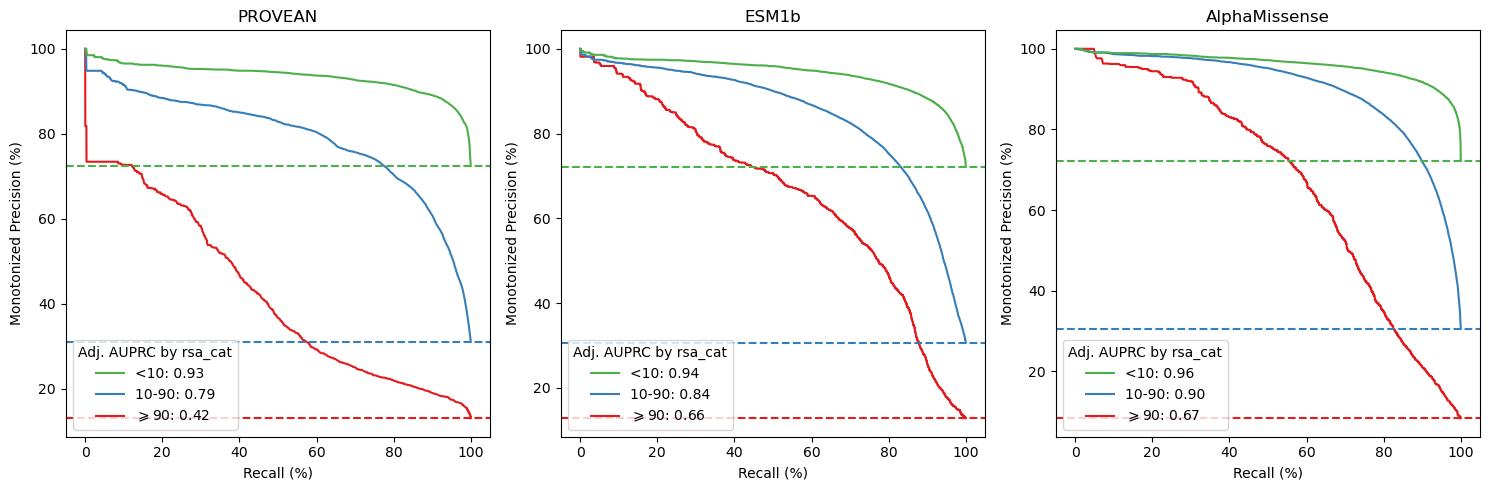

({'PROVEAN_converted_rankscore': {'$\\geqslant$90': {'AUPRC': 0.4205103661779058},
   '10-90': {'AUPRC': 0.7904188306660516},
   '<10': {'AUPRC': 0.9349158790293061}},
  'ESM1b_rankscore': {'$\\geqslant$90': {'AUPRC': 0.6586876725673212},
   '10-90': {'AUPRC': 0.8426368190254968},
   '<10': {'AUPRC': 0.9425810220299661}},
  'AlphaMissense_rankscore': {'$\\geqslant$90': {'AUPRC': 0.6718126114127385},
   '10-90': {'AUPRC': 0.8982587663783124},
   '<10': {'AUPRC': 0.9612452080927807}}},
 {})

In [21]:
plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label="1_Pathogenic", methods=methods, monotonized_flag=True, balanced_flag=False)

### yogiroc

__Derivation of Adjusted Precision Using Bayes’ Rule__

We start with the standard definition of precision (also known as the positive predictive value, PPV):

$\text{PPV} = \frac{TP}{TP + FP} = P(\text{True} \mid \text{Positive prediction})$

It is often useful to express this in terms of odds. The odds form of the PPV is given by

$\text{Odds}(\text{True} \mid \text{Positive}) = \frac{\text{PPV}}{1 - \text{PPV}}$

Now, let $\pi = P(\text{True})$ be the prior probability (baseline prevalence) of a true (positive) case. The baseline odds for a true case is

$\text{Odds}(\text{True}) = \frac{\pi}{1-\pi}$

To adjust the precision for the baseline rate, we “balance” the PPV by removing the influence of the prior. This is achieved by computing the ratio of the PPV odds to the baseline odds:

$\text{Balanced Odds} = \frac{\text{PPV}}{1 - \text{PPV}} \cdot \frac{1-\pi}{\pi}$

Finally, we convert these balanced odds back into a probability. Recall that converting odds \(O\) to probability is done by

$\text{Probability} = \frac{O}{1+O}$

Thus, the **Adjusted Precision** (or balanced precision) is given by


$\text{Balanced Precision} = \frac{\dfrac{\text{PPV}}{1 - \text{PPV}} \cdot \dfrac{1-\pi}{\pi}}{1 + \dfrac{\text{PPV}}{1 - \text{PPV}} \cdot \dfrac{1-\pi}{\pi}}$

With some algebra, this expression simplifies to:

$\text{Balanced Precision} = \frac{\text{PPV}(1-\pi)}{\text{PPV}(1-\pi) + (1-\text{PPV})\pi}$

This adjustment recalibrates the observed precision by accounting for the underlying class imbalance, yielding a metric that is more comparable across datasets or subgroups with different prior probabilities.

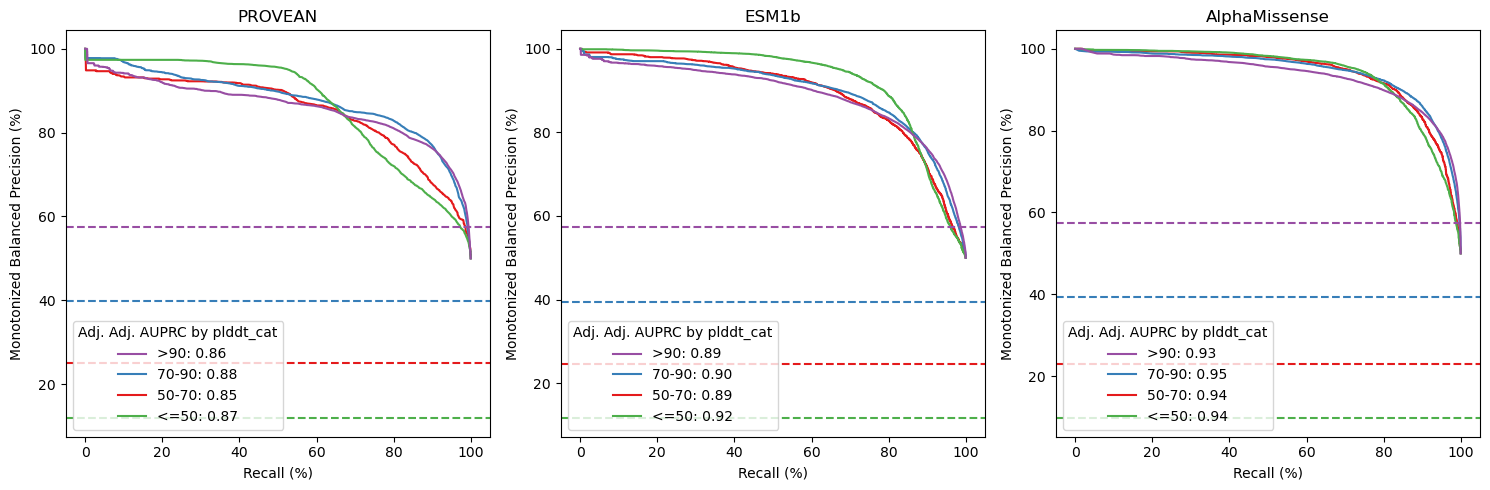

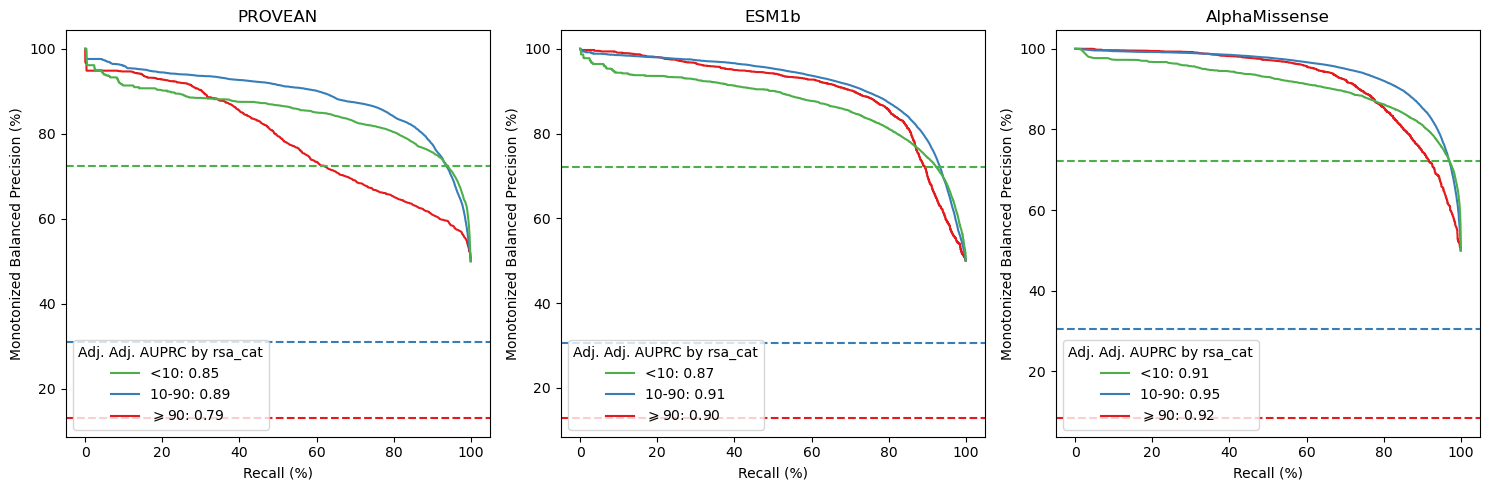

({'PROVEAN_converted_rankscore': {'$\\geqslant$90': {'AUPRC': 0.7866892277113822},
   '10-90': {'AUPRC': 0.8870168544937991},
   '<10': {'AUPRC': 0.849138882755198}},
  'ESM1b_rankscore': {'$\\geqslant$90': {'AUPRC': 0.8984668407241293},
   '10-90': {'AUPRC': 0.9146048295246348},
   '<10': {'AUPRC': 0.8695895946182688}},
  'AlphaMissense_rankscore': {'$\\geqslant$90': {'AUPRC': 0.9203471374378825},
   '10-90': {'AUPRC': 0.9468166564667696},
   '<10': {'AUPRC': 0.9090091099842158}}},
 {})

In [32]:
plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label="1_Pathogenic", methods=methods, monotonized_flag=True, balanced_flag=True)

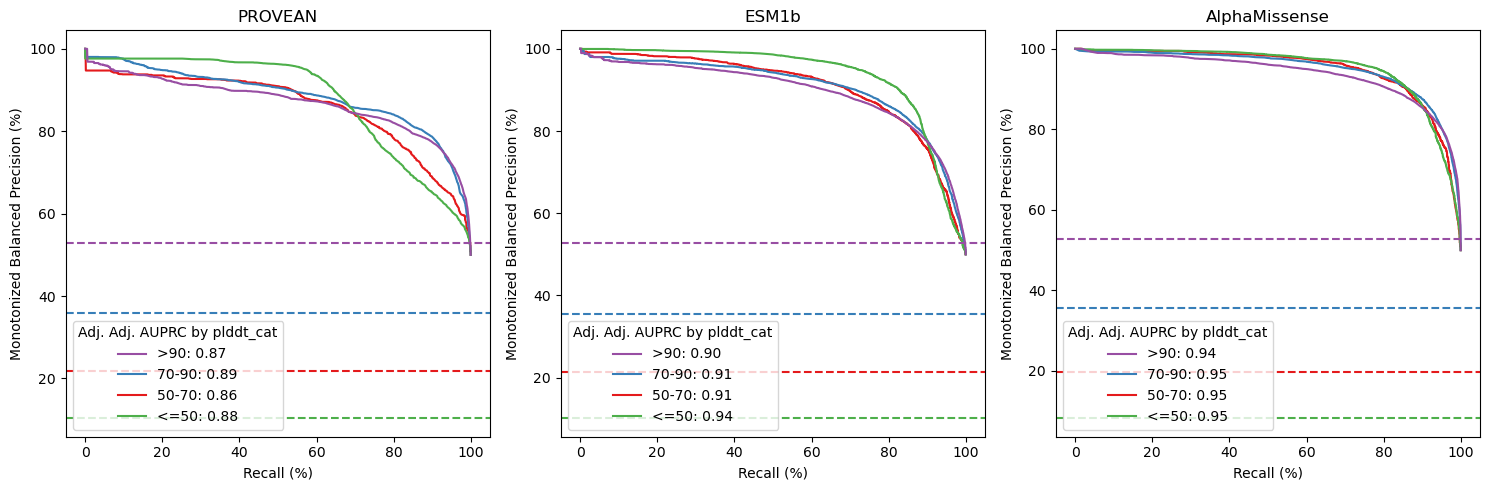

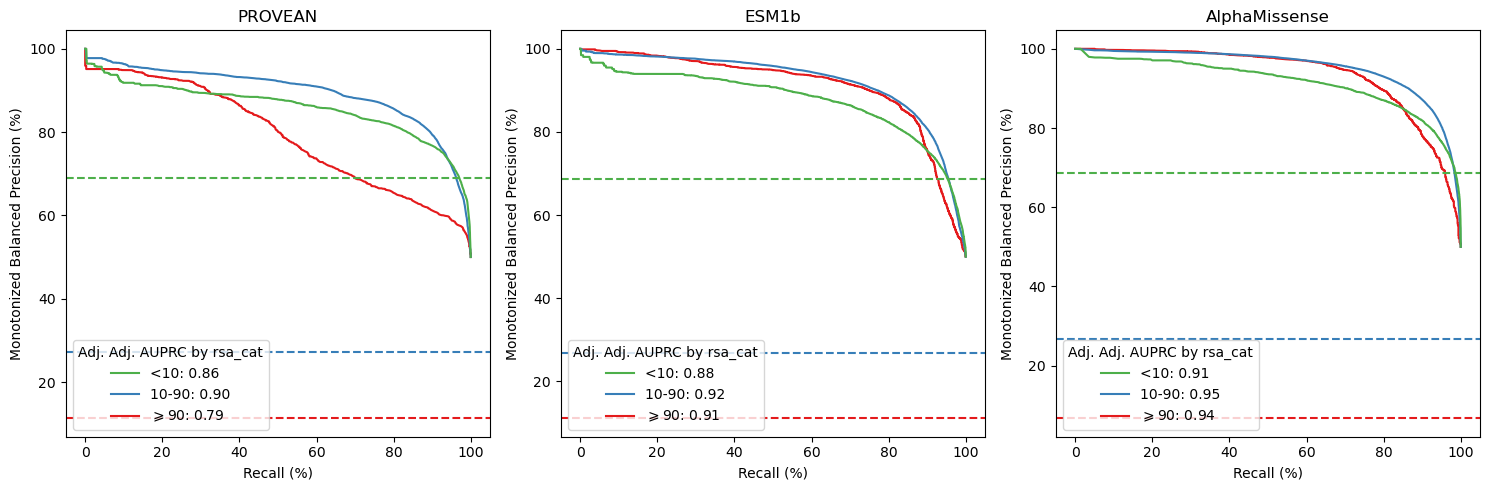

({'PROVEAN_converted_rankscore': {'$\\geqslant$90': {'AUPRC': 0.7907403969900262},
   '10-90': {'AUPRC': 0.8953300366858103},
   '<10': {'AUPRC': 0.8589233129090852}},
  'ESM1b_rankscore': {'$\\geqslant$90': {'AUPRC': 0.9111644311361737},
   '10-90': {'AUPRC': 0.9223273355598679},
   '<10': {'AUPRC': 0.877073739609604}},
  'AlphaMissense_rankscore': {'$\\geqslant$90': {'AUPRC': 0.9350352772345161},
   '10-90': {'AUPRC': 0.9520840484573536},
   '<10': {'AUPRC': 0.9149799551019513}}},
 {})

In [35]:
plot_adjusted_pr_curves(df_clinvar_w_scores.filter(pl.col("ReviewStatus").is_in([
                            'practice guideline'
                            'reviewed by expert panel',
                            'criteria provided, multiple submitters, no conflicts',
                            'criteria provided, single submitter'
                        ])), pos_label="1_Pathogenic", methods=methods, monotonized_flag=True, balanced_flag=True)

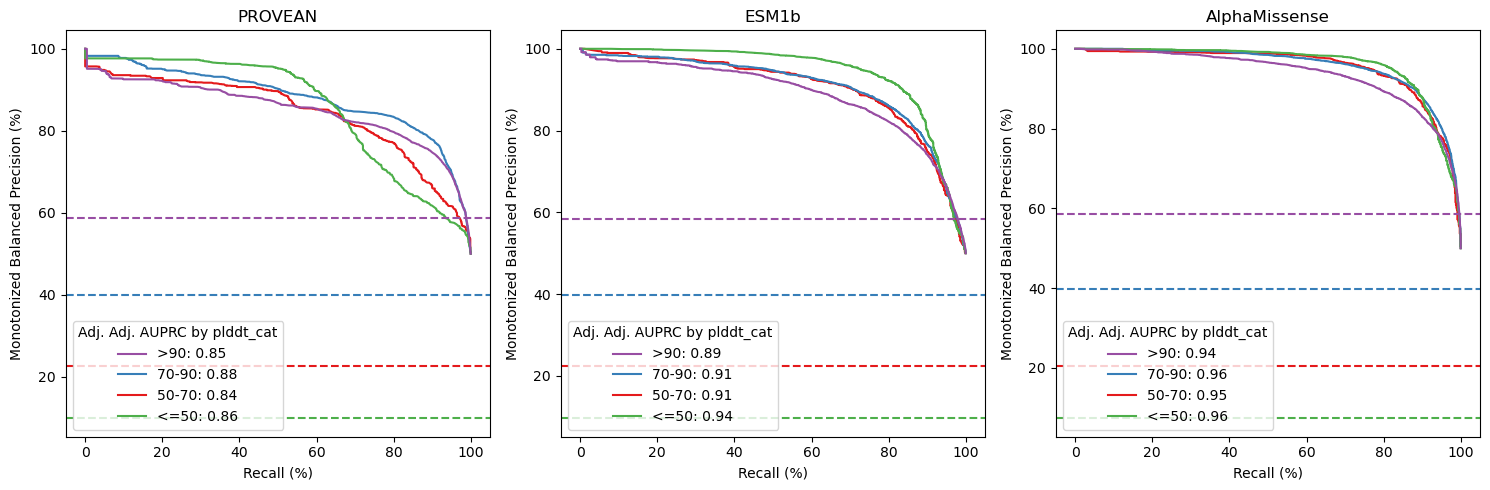

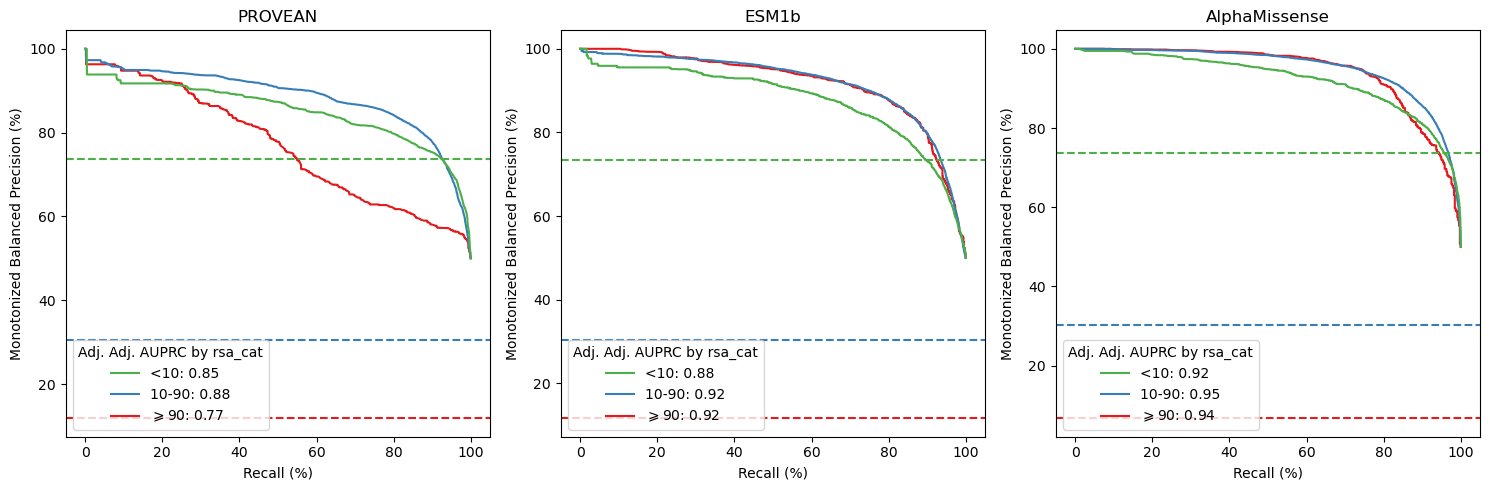

({'PROVEAN_converted_rankscore': {'$\\geqslant$90': {'AUPRC': 0.7674044274425753},
   '10-90': {'AUPRC': 0.8837635035373528},
   '<10': {'AUPRC': 0.8514028114780956}},
  'ESM1b_rankscore': {'$\\geqslant$90': {'AUPRC': 0.9179634946284363},
   '10-90': {'AUPRC': 0.9182060155149935},
   '<10': {'AUPRC': 0.8781821170657131}},
  'AlphaMissense_rankscore': {'$\\geqslant$90': {'AUPRC': 0.9426807705846623},
   '10-90': {'AUPRC': 0.9513993326400734},
   '<10': {'AUPRC': 0.9222097885319192}}},
 {})

In [33]:
plot_adjusted_pr_curves(df_clinvar_w_scores.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")!="3_Conflicting")), pos_label="1_Pathogenic", methods=methods, monotonized_flag=True, balanced_flag=True)